

<h2 style="border:2px solid #AA5E7A;border-radius:100%; padding:20px; margin:0; color:#AA5E7A; text-align:center">  Visualisation for the final report</h2>


In [2]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
import json

In [3]:
df=pd.read_csv('../../data/processed/employee_clean.csv')
metrics=json.load(open('../../reports/model_metrics.json'));
metrics

{'selected_model': 'Gradient Boosting',
 'test_accuracy': 0.929,
 'test_macro_f1': 0.891,
 'hiring_model_accuracy': 0.5167,
 'hiring_model_macro_f1': 0.3804,
 'baseline_accuracy': 0.7292,
 'top3': ['EmpEnvironmentSatisfaction',
  'EmpLastSalaryHikePercent',
  'YearsSinceLastPromotion']}

### Share of low performers (rating 2) by department

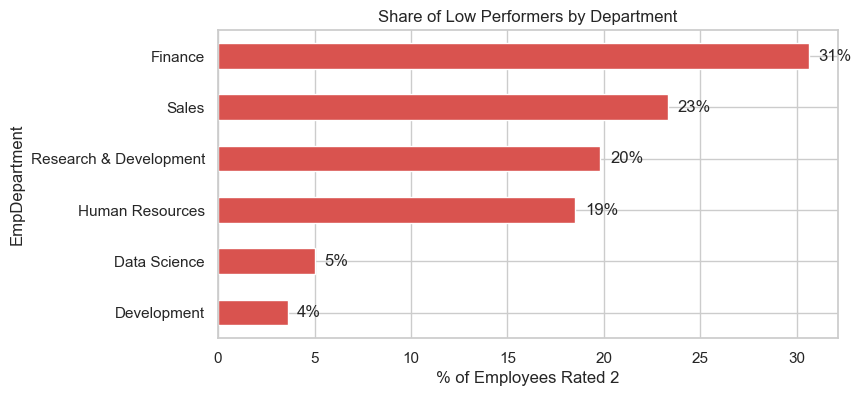

In [3]:
# Calculate percentage of low performers by department
s = (
    df.assign(low=df.PerformanceRating == 2)
    .groupby('EmpDepartment')
    .low.mean() * 100
).sort_values()


# Create horizontal bar chart
ax = s.plot(
    kind='barh',
    color='#d9534f',
    figsize=(8, 4)
)

# Set labels and title
ax.set_xlabel('% of Employees Rated 2')
ax.set_title('Share of Low Performers by Department')


# Add percentage labels to bars
for i, v in enumerate(s):
    ax.text(
        v + 0.5,
        i,
        f'{v:.0f}%',
        va='center'
    )

### The three main drivers

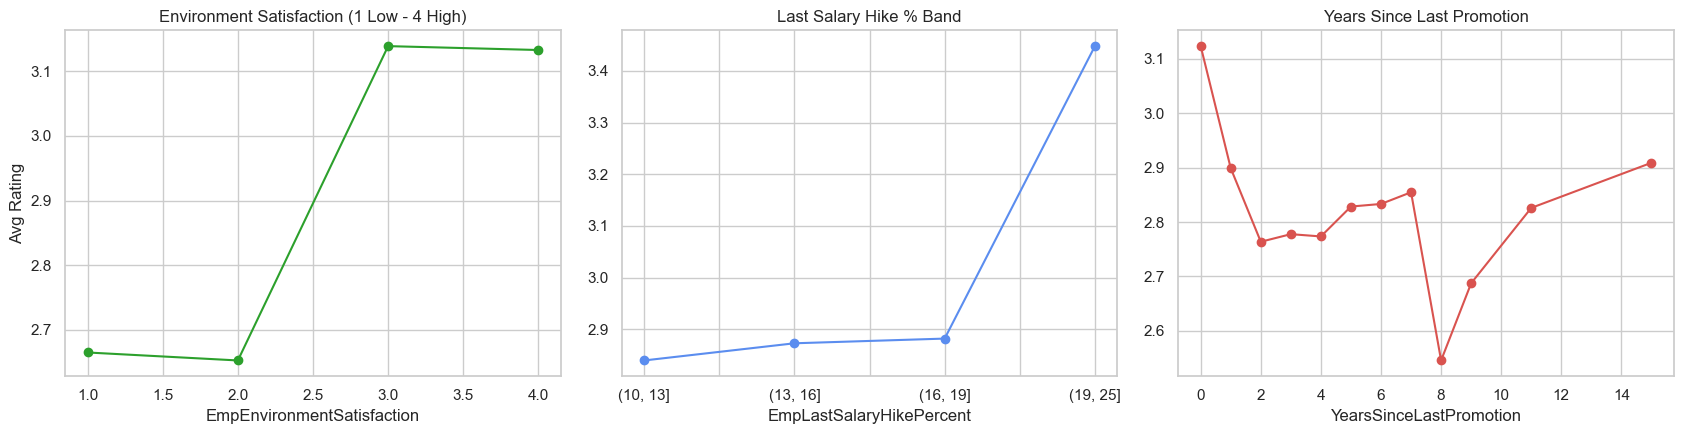

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Environment Satisfaction vs Performance Rating
l = df.groupby('EmpEnvironmentSatisfaction').PerformanceRating.mean()

l.plot(
    marker='o',
    ax=ax[0],
    color='#2ca02c'
)

ax[0].set_title('Environment Satisfaction (1 Low - 4 High)')
ax[0].set_ylabel('Avg Rating')


# 2. Last Salary Hike vs Performance Rating
b = pd.cut(
    df.EmpLastSalaryHikePercent,
    [10, 13, 16, 19, 25]
)

df.groupby(b, observed=True).PerformanceRating.mean().plot(
    marker='o',
    ax=ax[1],
    color='#5b8def'
)

ax[1].set_title('Last Salary Hike % Band')


# 3. Years Since Last Promotion vs Performance Rating
g = df.groupby('YearsSinceLastPromotion').PerformanceRating.agg(
    ['mean', 'count']
)

g = g[g['count'] >= 10]

g['mean'].plot(
    marker='o',
    ax=ax[2],
    color='#d9534f'
)

ax[2].set_title('Years Since Last Promotion')


# Adjust layout and display
plt.tight_layout()
plt.show()

### Model performance and model reliance

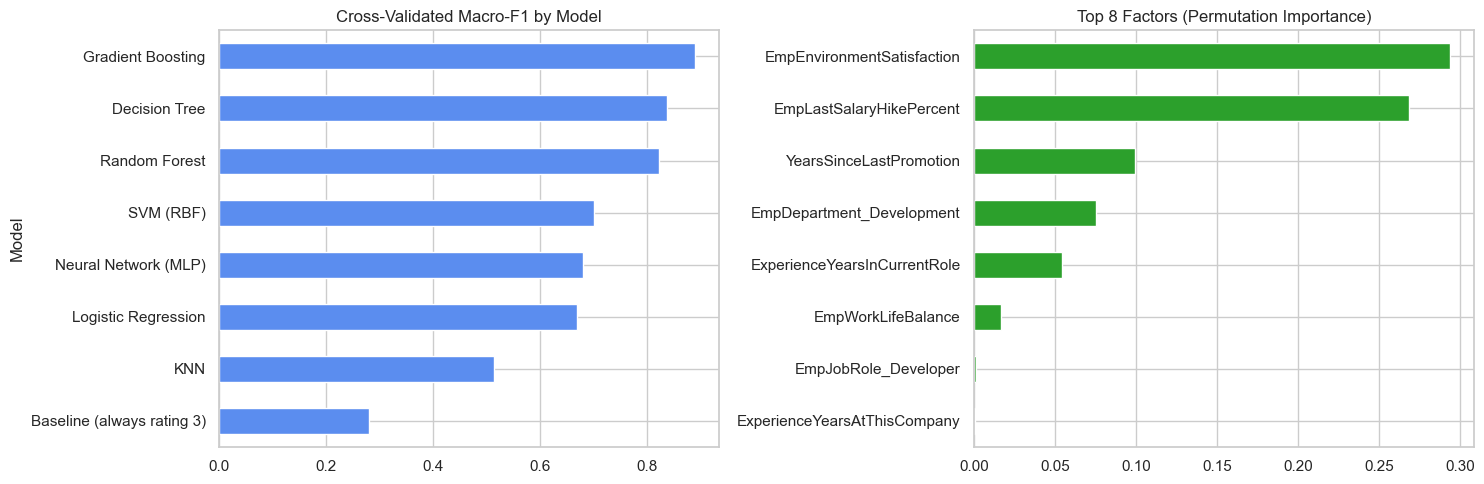

In [5]:
# Load model comparison and feature importance data
res = pd.read_csv('../../reports/model_comparison.csv')

imp = pd.read_csv(
    '../../reports/feature_importance.csv',
    index_col=0
).iloc[:, 0].head(8)


# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(15, 5))


# 1. Cross-validated macro-F1 by model
res.set_index('Model')['CV macro-F1'].sort_values().plot(
    kind='barh',
    ax=ax[0],
    color='#5b8def'
)

ax[0].set_title('Cross-Validated Macro-F1 by Model')


# 2. Top 8 factors (Permutation Importance)
imp[::-1].plot(
    kind='barh',
    ax=ax[1],
    color='#2ca02c'
)

ax[1].set_title('Top 8 Factors (Permutation Importance)')


# Adjust layout
plt.tight_layout()


plt.show()